# 01. Data and EDA

This notebook checks CIFAR-10 before any training: class balance, per-channel statistics, the train/val split and the augmentations.

In [1]:
import os

os.chdir("..")  # run from the repo root so paths match the scripts
import matplotlib.pyplot as plt
import numpy as np
import torch
from src.data import VAL_IDX, Batches, channel_stats, load_cifar, split_indices
from src.utils import CLASSES, FIG_DIR

x_train, y_train, x_test, y_test = load_cifar("data")
print(x_train.shape, x_test.shape)

(50000, 3, 32, 32) (10000, 3, 32, 32)


## Samples

Eight random images per class from the training set.

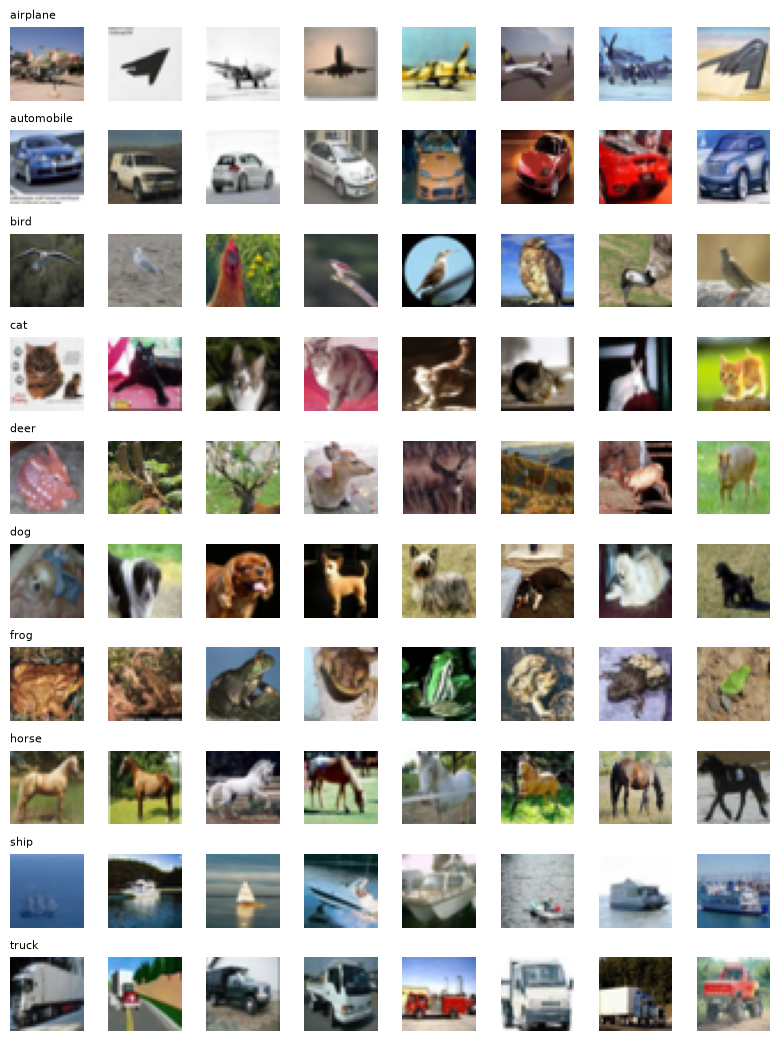

In [2]:
rng = np.random.default_rng(0)
fig, axes = plt.subplots(10, 8, figsize=(8, 10.5))
for row, name in enumerate(CLASSES):
    picks = rng.choice(np.where(y_train == row)[0], 8, replace=False)
    for col, i in enumerate(picks):
        axes[row, col].imshow(x_train[i].transpose(1, 2, 0))
        axes[row, col].axis("off")
    axes[row, 0].set_title(name, loc="left", fontsize=8)
fig.tight_layout()
FIG_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(FIG_DIR / "eda_samples.png", dpi=110)

## Class counts

The plan expects 5,000 images per class in train and 1,000 in test.

In [3]:
print("train", np.bincount(y_train))
print("test ", np.bincount(y_test))
assert (np.bincount(y_train) == 5000).all() and (np.bincount(y_test) == 1000).all()

train [5000 5000 5000 5000 5000 5000 5000 5000 5000 5000]
test  [1000 1000 1000 1000 1000 1000 1000 1000 1000 1000]


## Split and statistics

The 5,000 validation images come from the training set, stratified, with seed 42. The mean and std below come from the 45,000 remaining training images only.

In [4]:
train_idx, val_idx = split_indices(y_train, path=VAL_IDX)
print(len(train_idx), len(val_idx), "overlap:", len(set(train_idx) & set(val_idx)))
print("val per class", np.bincount(y_train[val_idx]))
mean, std = channel_stats(x_train[train_idx])
print("mean", np.round(mean, 4), "std", np.round(std, 4))

45000 5000 overlap: 0
val per class [500 500 500 500 500 500 500 500 500 500]


mean [0.4911 0.4821 0.4464] std [0.2469 0.2434 0.2616]


The CIFAR statistics sit close to the ImageNet ones (mean 0.485, 0.456, 0.406; std 0.229, 0.224, 0.225), so a mismatch would not hurt much. Each model still uses the statistics of its own training data.

## Augmentation check

Eight augmented versions of one image: random crop with 4 pixels of padding, then a random horizontal flip. The left image is the original.

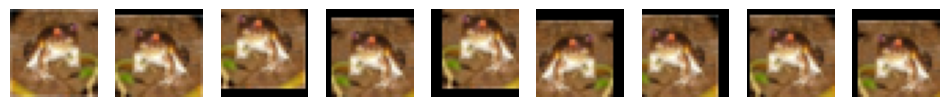

In [5]:
one = x_train[train_idx[:1]]
loader = Batches(np.repeat(one, 8, axis=0), np.zeros(8, dtype=int), 8, ([0, 0, 0], [1, 1, 1]), torch.device("cpu"), train=True, seed=3)
aug = next(iter(loader))[0]
fig, axes = plt.subplots(1, 9, figsize=(12, 1.6))
axes[0].imshow(one[0].transpose(1, 2, 0))
for ax, img in zip(axes[1:], aug):
    ax.imshow(img.permute(1, 2, 0).numpy())
for ax in axes:
    ax.axis("off")
fig.savefig(FIG_DIR / "eda_augment.png", dpi=110)